# Partitions sans fuite - PlantVillage - PFA 07

**Objectif :** produire les partitions entraînement / validation / test interne de PlantVillage **au niveau des feuilles**, et démontrer par des contrôles automatiques qu'aucune feuille, aucun cluster de quasi-doublons et aucun fichier identique ne se retrouve dans deux partitions.

**Principe**
1. On part du `manifest.csv` de l'audit (images conservées, classes retenues).
2. Chaque image est reliée à sa **feuille d'origine** grâce à `leaf_grouping/leaf-map.json`, fourni par les auteurs du corpus (la clé est le nom d'origine de la photo).
3. Les feuilles reliées par un cluster de quasi-doublons ou par un fichier identique sont **fusionnées** en un seul groupe.
4. Les **groupes** (et non les images) sont répartis 70 / 15 / 15 dans chaque classe, avec une graine fixe.
5. Des contrôles (`assert`) vérifient l'absence de chevauchement.

**Choix méthodologique important :** `leaf-map.json` ne couvre qu'une partie des images. Les images **sans feuille identifiée** ne sont pas utilisées dans les partitions (réserve séparée) : les regrouper à partir des numéros de fichiers n'est pas fiable (voir la section 2).

**Prérequis :** avoir exécuté l'audit (`manifest.csv`) et cloné `leaf_grouping/` (voir le clonage partiel).

## 0. Configuration

In [1]:
from pathlib import Path

MANIFEST = Path("audit/pv/manifest.csv")                                    # manifeste de l'audit PlantVillage
LEAF_MAP = Path("PlantVillage-Dataset/leaf_grouping/leaf-map.json")         # regroupement par feuille (auteurs du corpus)
OUT = Path("partitions/pv")                                                 # dossier de sortie
RATIOS = {"train": 0.70, "val": 0.15, "test": 0.15}
SEED = 42

## 1. Imports et chargement du manifeste

In [2]:
import hashlib, json, platform, re, subprocess, sys
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

assert abs(sum(RATIOS.values()) - 1) < 1e-9, "Les proportions doivent sommer à 1"
OUT.mkdir(parents=True, exist_ok=True)
pd.set_option("display.max_columns", 50, "display.width", 200)

man = pd.read_csv(MANIFEST)
elig = man[man["kept_for_dataset"].astype(bool) & (man["class_retained"] != "hors_perimetre")].copy()
print(f"{len(man)} images au manifeste -> {len(elig)} éligibles (conservées, dans le périmètre).")

not_ok = elig[elig["class_status"] != "CONFIRME"]
if len(not_ok):
    print(f"ATTENTION : {len(not_ok)} images appartiennent à des classes dont le statut n'est pas CONFIRME.")

display(elig.groupby("class_retained").size().rename("n_images").reset_index())
print("Tableau 1 - Images éligibles par classe retenue (après exclusions de l'audit).")

18160 images au manifeste -> 7209 éligibles (conservées, dans le périmètre).


,class_retained,n_images
0,alternariose_precoce,1000
1,cladosporiose,952
2,mildiou_tardif,1901
3,saine,1585
4,septoriose,1771


Tableau 1 - Images éligibles par classe retenue (après exclusions de l'audit).


## 2. Rattachement des images aux feuilles

La clé de `leaf-map.json` est le **nom d'origine de la photo** (partie après `___` dans le nom du fichier, sans extension, en minuscules). Une même clé peut exister pour plusieurs cultures : on ne retient que les identifiants de feuille de la **même classe** que le dossier de l'image.

> **Pourquoi ne pas regrouper les images sans carte par numéros de fichiers consécutifs ?** Testé sur les images cartographiées : même avec un écart de 1, 59 à 224 feuilles sur 250 (selon la classe) ont leurs images dispersées sur plusieurs plages de numéros. Cette heuristique laisserait donc des fuites ; on l'écarte.

In [3]:
def leaf_key(relpath: str) -> str:
    fname = relpath.split("/")[-1]
    stem = fname.rsplit(".", 1)[0]
    name = stem.split("___", 1)[1] if "___" in stem else stem
    return name.lower().strip()


leaf_map = json.loads(LEAF_MAP.read_text(encoding="utf-8"))
elig["leaf_key"] = elig["relpath"].map(leaf_key)
elig["leaf_ids"] = [[x for x in leaf_map.get(r.leaf_key, []) if x.split(":::")[0] == r.class_origin]
                    for r in elig.itertuples()]
elig["mapped"] = elig["leaf_ids"].map(bool)
elig["source"] = elig["leaf_key"].map(lambda k: re.split(r"\s+(?:leaf\b|\d)", k, maxsplit=1)[0])

cov = (elig.groupby("class_retained")["mapped"].agg(n_images="size", cartographiees="sum").reset_index())
cov["non_cartographiees"] = cov["n_images"] - cov["cartographiees"]
cov["taux_couverture_%"] = (100 * cov["cartographiees"] / cov["n_images"]).round(1)
display(cov)
print("Tableau 2 - Couverture de leaf-map.json par classe : seules les images cartographiées entrent dans les partitions.")

core = elig[elig["mapped"]].copy()
reserve = elig[~elig["mapped"]].copy()
print(f"Sous-ensemble partitionné : {len(core)} images ; réserve non cartographiée : {len(reserve)} images.")

,class_retained,n_images,cartographiees,non_cartographiees,taux_couverture_%
0,alternariose_precoce,1000,999,1,99.9
1,cladosporiose,952,952,0,100.0
2,mildiou_tardif,1901,920,981,48.4
3,saine,1585,999,586,63.0
4,septoriose,1771,1000,771,56.5


Tableau 2 - Couverture de leaf-map.json par classe : seules les images cartographiées entrent dans les partitions.
Sous-ensemble partitionné : 4870 images ; réserve non cartographiée : 2339 images.


### Origine des images (source) par classe

Attention : si chaque classe provient d'une **seule source** d'acquisition, le modèle peut apprendre la signature de la source (appareil, fond, éclairage) au lieu de la maladie. À discuter dans le rapport.

In [4]:
src_core = pd.crosstab(core["class_retained"], core["source"])
display(src_core)
print("Tableau 3 - Sources d'acquisition par classe dans le sous-ensemble partitionné (nombre d'images).")

src_res = pd.crosstab(reserve["class_retained"], reserve["source"])
display(src_res.loc[:, (src_res.sum() > 0)])
print("Tableau 4 - Sources d'acquisition par classe dans la réserve non cartographiée (non utilisée dans les partitions).")

source,crnl_l.mold,matt.s_cg,rs_erly.b,rs_hl,rs_late.b
class_retained,,,,,
alternariose_precoce,0,0,999,0,0
cladosporiose,952,0,0,0,0
mildiou_tardif,0,0,0,0,920
saine,0,0,0,999,0
septoriose,0,1000,0,0,0


Tableau 3 - Sources d'acquisition par classe dans le sous-ensemble partitionné (nombre d'images).


source,2700323949_95aa2eaa01_o,cg1,gh_hl,ghlb,ghlb2,ghlb2es,ghlb_ps,jr_sept.l.s,keller.st_cg,rs_erly.b
class_retained,,,,,,,,,,
alternariose_precoce,0,0,0,0,0,0,0,0,0,1
mildiou_tardif,0,0,2,66,740,27,146,0,0,0
saine,1,1,584,0,0,0,0,0,0,0
septoriose,0,0,0,0,0,0,0,497,274,0


Tableau 4 - Sources d'acquisition par classe dans la réserve non cartographiée (non utilisée dans les partitions).


## 3. Construction des groupes

Deux feuilles sont **fusionnées** si : (a) une image est associée à plusieurs identifiants de feuille de la même classe, (b) deux images appartiennent au même cluster de quasi-doublons (règle de décision de l'audit), ou (c) deux images ont le même SHA-256.

In [5]:
parent = {}


def find(x):
    parent.setdefault(x, x)
    while parent[x] != x:
        parent[x] = parent[parent[x]]
        x = parent[x]
    return x


def union(a, b):
    ra, rb = find(a), find(b)
    if ra != rb:
        parent[rb] = ra


for ids in core["leaf_ids"]:
    find(ids[0])
    for other in ids[1:]:
        union(ids[0], other)

for _, g in core[core["near_dup_cluster"] >= 0].groupby("near_dup_cluster"):
    first = g["leaf_ids"].iloc[0][0]
    for ids in g["leaf_ids"]:
        union(first, ids[0])

for _, g in core.groupby("sha256"):
    if len(g) > 1:
        first = g["leaf_ids"].iloc[0][0]
        for ids in g["leaf_ids"]:
            union(first, ids[0])

core["root"] = [find(ids[0]) for ids in core["leaf_ids"]]
gid = {r: f"G{k:05d}" for k, r in enumerate(sorted(core["root"].unique()))}
core["group_id"] = core["root"].map(gid)

n_leaves = len({i for ids in core["leaf_ids"] for i in ids})
print(f"{n_leaves} feuilles identifiées -> {core['group_id'].nunique()} groupes après fusion.")
sizes = core.groupby("group_id").size()
display(sizes.describe().round(2).to_frame("images par groupe").T)
print("Tableau 5 - Distribution du nombre d'images par groupe (un groupe = une feuille ou plusieurs feuilles fusionnées).")

1218 feuilles identifiées -> 1218 groupes après fusion.


,count,mean,std,min,25%,50%,75%,max
images par groupe,1218.0,4.0,0.04,3.0,4.0,4.0,4.0,4.0


Tableau 5 - Distribution du nombre d'images par groupe (un groupe = une feuille ou plusieurs feuilles fusionnées).


## 4. Répartition par groupes, stratifiée par classe

Pour chaque classe, les groupes sont mélangés (graine fixe) puis affectés à `train`, `val`, `test` jusqu'à atteindre les proportions visées en **nombre d'images**. Un groupe n'est jamais coupé.

In [6]:
groups = (core.groupby("group_id")
          .agg(n_images=("image_id", "size"),
               classes=("class_retained", lambda s: "; ".join(sorted(set(s)))),
               primary_class=("class_retained", lambda s: s.value_counts().idxmax()),
               n_leaf_ids=("leaf_ids", lambda s: len({i for ids in s for i in ids})))
          .reset_index())
groups["partition"] = ""

rng = np.random.default_rng(SEED)
for cls, g in groups.groupby("primary_class"):          # ordre alphabétique : reproductible
    g = g.iloc[rng.permutation(len(g))]
    total, acc = g["n_images"].sum(), 0
    for idx, n in zip(g.index, g["n_images"]):
        frac = acc / total
        groups.at[idx, "partition"] = ("train" if frac < RATIOS["train"]
                                       else "val" if frac < RATIOS["train"] + RATIOS["val"] else "test")
        acc += n

core["partition"] = core["group_id"].map(groups.set_index("group_id")["partition"])
print("Groupes multi-classes :", int((groups["classes"].str.contains(";")).sum()))

Groupes multi-classes : 0


## 5. Contrôles anti-fuite (doivent tous réussir)

In [7]:
def check(name: str, cond: bool) -> None:
    print(("OK     " if cond else "ECHEC  ") + name)
    assert cond, f"Contrôle échoué : {name}"


check("toutes les images ont une partition", core["partition"].isin(RATIOS).all())
check("image_id unique (aucune image dans deux partitions)", core["image_id"].is_unique)
check("chaque groupe est dans une seule partition", (core.groupby("group_id")["partition"].nunique() == 1).all())
leaf_parts = core.explode("leaf_ids").groupby("leaf_ids")["partition"].nunique()
check("aucune feuille (leaf id) dans plusieurs partitions", (leaf_parts == 1).all())
cl = core[core["near_dup_cluster"] >= 0].groupby("near_dup_cluster")["partition"].nunique()
check("aucun cluster de quasi-doublons à cheval sur deux partitions", bool((cl == 1).all()) if len(cl) else True)
check("aucun fichier identique (SHA-256) dans plusieurs partitions", (core.groupby("sha256")["partition"].nunique() == 1).all())
print("\nTous les contrôles anti-fuite sont réussis.")

OK     toutes les images ont une partition
OK     image_id unique (aucune image dans deux partitions)
OK     chaque groupe est dans une seule partition
OK     aucune feuille (leaf id) dans plusieurs partitions
OK     aucun cluster de quasi-doublons à cheval sur deux partitions
OK     aucun fichier identique (SHA-256) dans plusieurs partitions

Tous les contrôles anti-fuite sont réussis.


## 6. Résultats

partition,train,val,test,total
class_retained,,,,
alternariose_precoce,703,148,148,999
cladosporiose,668,144,140,952
mildiou_tardif,644,140,136,920
saine,703,148,148,999
septoriose,700,152,148,1000


Tableau 6 - Nombre d'images par classe et par partition.


partition,train,val,test
class_retained,,,
alternariose_precoce,70.4,14.8,14.8
cladosporiose,70.2,15.1,14.7
mildiou_tardif,70.0,15.2,14.8
saine,70.4,14.8,14.8
septoriose,70.0,15.2,14.8


Tableau 7 - Proportion (%) de chaque partition par classe (cibles : 70 / 15 / 15).


partition,train,val,test
primary_class,,,
alternariose_precoce,176,37,37
cladosporiose,167,36,35
mildiou_tardif,161,35,34
saine,176,37,37
septoriose,175,38,37


Tableau 8 - Nombre de groupes (feuilles) par classe et par partition.


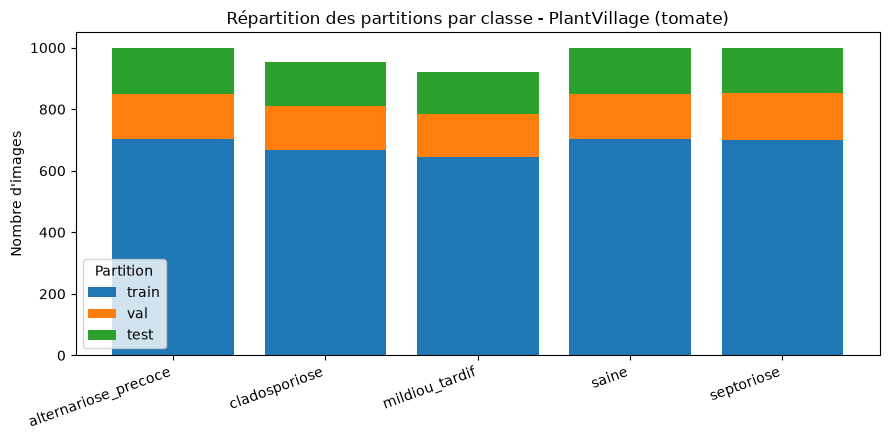

Figure 1 - Répartition entraînement / validation / test par classe, après partition par groupes de feuilles.


In [8]:
cnt = pd.crosstab(core["class_retained"], core["partition"])[list(RATIOS)]
cnt["total"] = cnt.sum(axis=1)
display(cnt)
print("Tableau 6 - Nombre d'images par classe et par partition.")

pct = (cnt[list(RATIOS)].div(cnt["total"], axis=0) * 100).round(1)
display(pct)
print("Tableau 7 - Proportion (%) de chaque partition par classe (cibles : 70 / 15 / 15).")

gcnt = pd.crosstab(groups["primary_class"], groups["partition"])[list(RATIOS)]
display(gcnt)
print("Tableau 8 - Nombre de groupes (feuilles) par classe et par partition.")

fig, ax = plt.subplots(figsize=(9, 4.5))
bottom = np.zeros(len(cnt))
for part in RATIOS:
    ax.bar(cnt.index, cnt[part], bottom=bottom, label=part)
    bottom += cnt[part].to_numpy()
ax.set_ylabel("Nombre d'images")
ax.set_title("Répartition des partitions par classe - PlantVillage (tomate)")
ax.legend(title="Partition")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.savefig(OUT / "fig_partitions.png", dpi=150)
plt.show()
print("Figure 1 - Répartition entraînement / validation / test par classe, après partition par groupes de feuilles.")

## 7. Sauvegarde des livrables

In [9]:
def md_table(d: pd.DataFrame) -> str:
    d = d.reset_index() if d.index.name else d.copy()
    head = "| " + " | ".join(map(str, d.columns)) + " |"
    sep = "|" + "|".join("---" for _ in d.columns) + "|"
    body = ["| " + " | ".join(str(v) for v in r) + " |" for r in d.itertuples(index=False)]
    return "\n".join([head, sep] + body)


def sha256_file(p: Path) -> str:
    return hashlib.sha256(p.read_bytes()).hexdigest()


def git_commit() -> str:
    try:
        return subprocess.check_output(["git", "rev-parse", "HEAD"], stderr=subprocess.DEVNULL, text=True).strip()
    except Exception:
        return ""


out_cols = ["image_id", "relpath", "class_origin", "class_retained", "group_id", "partition", "near_dup_cluster", "sha256"]
part_df = core[out_cols].copy()
part_df["leaf_ids"] = core["leaf_ids"].map(";".join)
part_df.sort_values(["partition", "class_retained", "image_id"]).to_csv(OUT / "partition.csv", index=False)
for p in RATIOS:
    (part_df[part_df["partition"] == p][["relpath", "class_retained"]]
     .rename(columns={"class_retained": "label"}).sort_values("relpath").to_csv(OUT / f"{p}.csv", index=False))
groups.to_csv(OUT / "groups.csv", index=False)
reserve[["image_id", "relpath", "class_retained", "source"]].to_csv(OUT / "reserve_non_cartographiee.csv", index=False)

config = {
    "date_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"),
    "seed": SEED, "ratios": RATIOS,
    "manifest": str(MANIFEST), "manifest_sha256": sha256_file(MANIFEST),
    "leaf_map": str(LEAF_MAP), "leaf_map_sha256": sha256_file(LEAF_MAP),
    "n_eligibles": int(len(elig)), "n_partitionnees": int(len(core)), "n_reserve": int(len(reserve)),
    "n_groupes": int(core["group_id"].nunique()),
    "versions": {"python": sys.version.split()[0], "numpy": np.__version__, "pandas": pd.__version__},
    "platform": platform.platform(), "git_commit": git_commit(),
}
(OUT / "partition_config.json").write_text(json.dumps(config, indent=2, ensure_ascii=False), encoding="utf-8")

report = f"""# Rapport de partition - PlantVillage (tomate)

*Généré le {config['date_utc']} UTC - graine {SEED} - empreinte du manifeste `{config['manifest_sha256'][:16]}...` - empreinte de leaf-map `{config['leaf_map_sha256'][:16]}...`*

## Synthèse
- Images éligibles : **{len(elig)}** ; partitionnées (feuille identifiée) : **{len(core)}** ; réserve non cartographiée : **{len(reserve)}**.
- Groupes (feuilles après fusion) : **{core['group_id'].nunique()}**.
- Contrôles anti-fuite : **tous réussis** (feuilles, groupes, clusters de quasi-doublons, SHA-256).

## Couverture de leaf-map.json
{md_table(cov)}

*Tableau 1 - Couverture du regroupement par feuille, par classe.*

## Images par classe et par partition
{md_table(cnt)}

*Tableau 2 - Effectifs (images).*

{md_table(pct)}

*Tableau 3 - Proportions (%) par classe.*

{md_table(gcnt)}

*Tableau 4 - Nombre de groupes (feuilles) par partition.*

## Sources d'acquisition par classe (sous-ensemble partitionné)
{md_table(src_core)}

*Tableau 5 - Nombre d'images par source et par classe.*

## Règle appliquée
Les partitions sont définies au niveau des feuilles (identifiants fournis par les auteurs du corpus) ; les feuilles reliées par un cluster de quasi-doublons ou par un fichier identique sont fusionnées ; les groupes sont répartis de façon stratifiée par classe, avec une graine fixe, avant toute augmentation. Les images sans identifiant de feuille sont mises de côté.
"""
(OUT / "partition_report.md").write_text(report, encoding="utf-8")
print(f"Livrables écrits dans {OUT.resolve()}")

Livrables écrits dans C:\Users\ayman\Desktop\PFA\Code Source\partitions\pv


## 8. À consigner dans le rapport n°2

**Phrase de méthode :**
> « Les partitions de PlantVillage sont définies au niveau des feuilles à partir du regroupement fourni par les auteurs du corpus (`leaf-map.json`) ; les feuilles reliées par un cluster de quasi-doublons ou par un fichier identique sont fusionnées, puis les groupes sont répartis 70 / 15 / 15 de façon stratifiée par classe, avec une graine fixe, avant toute augmentation. Des contrôles automatiques vérifient qu'aucune feuille, aucun cluster et aucun fichier identique n'apparaît dans deux partitions. »

**Limites à signaler**
1. Seules les images dotées d'un identifiant de feuille sont partitionnées ; les autres sont mises en réserve (Tableau 2), faute de regroupement fiable.
2. Dans le sous-ensemble partitionné, une classe correspond à une source d'acquisition (Tableau 3) : source et classe sont confondues. Le test externe PlantDoc et l'analyse Grad-CAM du fond sont donc d'autant plus importants.
3. Les identifiants de feuille supposent que `leaf-map.json` est exact et complet pour les images cartographiées.

**Points à discuter avec l'encadrant :** utilisation éventuelle de la réserve non cartographiée (par exemple comme test supplémentaire d'un changement de source), et conservation du découpage 70/15/15.